# 03 | The next WorldGym RL experiment

**9 minutes | Core question: What minimal comparison would establish useful world-model improvement?**

Read the narrative and saved outputs directly. Code cells provide optional CPU checks. Evidence snapshot: October 15, 2026.

![Proposed, not run: compare a replay-only world-model control W0 with dynamic/contact-data repair W1, hold the SFT start, reward and GRPO budget fixed, and test both policies in new MuJoCo scenes.](media/figures/03_next_rl.png)

[Open the full-size teaching image](media/figures/03_next_rl.png). AI-generated schematic; actual experiment images and numerical evidence appear below.

**How to read the image:** Follow the parallel W0 and W1 paths. World-model training changes the data mixture; policy training holds the starting policy, reward and budget fixed. W1 minus W0 tests the repair, while W1 minus SFT tests the net RL gain. RNG means random-number settings.

> **Remember:** This is an unexecuted proposal. A repair benefit and a net RL benefit require different comparisons.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'briefing_utils.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic('matplotlib', 'inline')
from briefing_utils import *
assert verify_assets() > 0

## The proposed research question

**Can better action and contact prediction make VLM scores on imagined trajectories more useful for the physical task, and produce an attributable RL improvement?**

This is a hypothesis motivated by local negative results. **The experiment has not been run, and no gain is promised.** The development-selected and independently confirmed SmolVLA SFT checkpoint is a reusable starting point: it scored 53/100 in R3. ACT40 remains a strong reference. Neither number predicts performance on the next test set.

## Why prioritize motion and contact rather than more static data?

The following plot uses the previous experiment's real saved results. The static scene becomes more stable while moving predictions worsen. For pickup, predicting contact, grasping and lifting is more directly related to task success than keeping the background still.

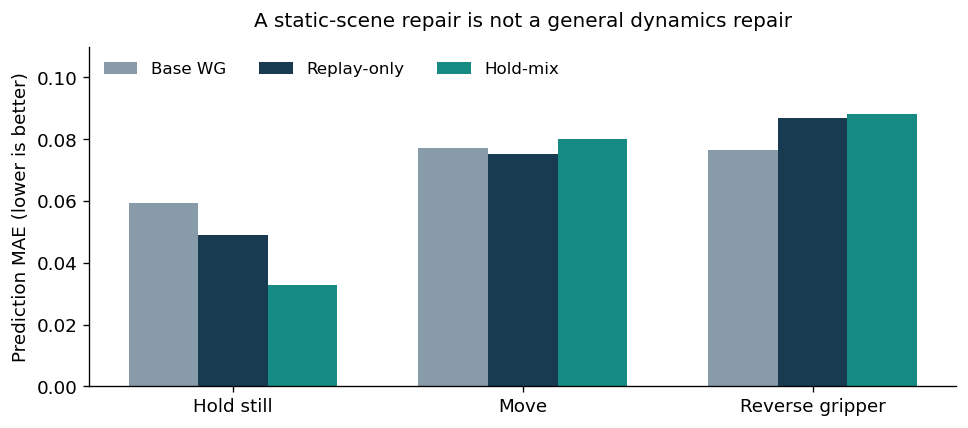

In [2]:
model_action_plot()

## A bounded next experiment

| Stage | Action | Decision evidence |
|---|---|---|
| 1. Collect new paired development data | Provisionally use 20 new initial states and four action variants; cover success, failure and near-contact behavior using the current policy and perturbations; run identical states/actions in MuJoCo and native WorldGym | Success coverage, action effects, contact/lift consistency; record physics and model-call costs |
| 2. Change one world-model factor | From the same initial model and with matched optimizer steps, compare replay-only data with a mixture of new on-policy motion/contact data; separate fit and validation initial states | Action fidelity and task ranking on the same new development set, not only static MAE |
| 3. Check reward in the generated domain | Initially hold reward fixed; compare imagined-trajectory ranking with paired physical results and inspect both error classes | If reward is the dominant error, repair it separately on development data, validate on fresh scenes, then freeze the same reward for all RL arms |
| 4. Run matched RL | Hold the SFT start, action distribution, initial states, group count and update count fixed; vary environment/model version | Freeze the complete design, then evaluate all five arms on new MuJoCo scenes |
| 5. Expand only after understanding one update | Add training seeds, larger Dyna iterations or more TTT conditions when justified | Reproducible improvement before scaling |

**Two labels must stay separate.** Physical success under an action sequence does not imply that its generated video visibly shows success. Record both physical task success and visible completion in generated images, with image review. The first tests whether the world model predicts task outcomes; the second helps identify VLM perception errors. They are not interchangeable labels.

If development data are nearly all failures, high reward accuracy is not evidence that reward can guide RL. Obtain successful development trajectories without changing the final test distribution. The previous four-initial-state diagnostic cannot substitute for this check.

## The five-arm matrix isolates the world-model version

| Arm | How the policy is obtained | Purpose |
|---|---|---|
| SFT | Freeze the existing SmolVLA checkpoint | Common RL starting point |
| M: MuJoCo RL | MuJoCo future observations, the same frozen VLM reward and GRPO | Physics-simulation training reference |
| W0: replay-control WorldGym RL | Match world-model updates from the same starting model using only replay data; same reward and GRPO | Control extra world-model training itself |
| W1: dynamic-repair WorldGym RL | Same starting model and update count, but include new motion/contact data; same reward and GRPO | Main method; isolate the targeted data intervention against W0 |
| ACT40 | Freeze the existing ACT checkpoint | Strong policy reference; its different architecture prevents it from being the sole causal control |

**Prespecify W1 - W0 as the primary comparison, and also report W1 - SFT, W1 - M and the ACT40 gap.** W1 must exceed the starting SFT for a net RL gain; it must exceed W0 to support this repair's increment. W1 beating W0 while remaining below SFT is a possible result that must be retained.

For a one-training-seed MVP, provisionally use **16 groups of four trajectories per RL arm**, keep fixed endpoints and retain failed trajectories. First measure a four-trajectory pilot, reward inference and optimizer time. Freeze feasible group counts before training, not after viewing final labels. At least three training seeds would be a reasonable next confirmation step before claiming stable gains; the number alone does not certify reliability.

Provisionally evaluate the five arms on **100 new initial states** disjoint from all historical fit/development/final scenes. Make the new physical data available to all relevant controls and report their cost separately. W0 and W1 share a reward checkpoint. Changing reward at the same time requires a separate matched ablation.

This matrix tests the RL increment of a world-model repair. A stronger question, whether the same new data are better spent on model-based RL than continued SFT, requires an additional matched-data Iter-SFT arm. The current draft does not answer that question.

## What would make the next step worth expanding?

Report official successes, paired gains and new failures, scene-paired 95% intervals, VLM false positives/negatives, physical interactions, model calls and wall time. Equal rollout counts do not mean equal runtime; sample budgets and time costs are different measurements.

If imagined rewards rise without higher MuJoCo success, inspect model error or reward exploitation. Better VLM scores, attractive videos or lower training loss are not substitutes for improved task success.

In [3]:
# Extrapolate only physical evaluation cost, not RL throughput or performance.
means = {r['policy']: r['mean_seconds'] for r in data('repair_results.json')['policies']}
seconds = 100 * (4 * means['SFT_mixed_scaled_lr'] + means['ACT40'])
table([
    ['Physical evaluation: 5 arms x 100 scenes', f'About {seconds/3600:.2f} hours', 'Historical per-scene extrapolation; excludes training, generation, reward and reporting'],
    ['Model-based RL throughput', 'Measure a four-trajectory pilot first', 'Model, reward and offload all affect time'],
    ['Expected success-rate gain', 'Unknown', 'Requires a new complete confirmation matrix'],
], ['Item', 'Estimate or status', 'Interpretation'])

Item,Estimate or status,Interpretation
Physical evaluation: 5 arms x 100 scenes,About 2.08 hours,"Historical per-scene extrapolation; excludes training, generation, reward and reporting"
Model-based RL throughput,Measure a four-trajectory pilot first,"Model, reward and offload all affect time"
Expected success-rate gain,Unknown,Requires a new complete confirmation matrix


## Two questions for a research discussion

1. In this single-task transfer, should the world model prioritize **ranking fidelity for action/contact outcomes** over aggregate pixel error?
2. How should generated-domain reward evaluation distinguish failure to generate success from failure to recognize it, and use that distinction to choose shorter rollouts or better data coverage?

The implementation and negative results make these concrete questions. They do not require a claim of established performance gain.

<details><summary>Reusable protocol draft: writes only inside this briefing</summary>

The next cell saves a discussion draft. Exact seed lists and the time budget remain unset until historical seed separation and pilot throughput are checked. It does not download a model, execute MuJoCo, start a GPU queue or change any old experiment.

</details>

In [4]:
draft = {
  'status': 'DRAFT_NOT_EXECUTED',
  'hypothesis': 'On-policy motion/contact data improves native world-model utility for downstream RL.',
  'primary_comparison': 'W1_dynamic_data_native_GRPO minus W0_replay_control_native_GRPO',
  'arms': ['frozen_SFT', 'M_MuJoCo_GRPO', 'W0_replay_control_native_GRPO', 'W1_dynamic_data_native_GRPO', 'frozen_ACT40'],
  'world_model_control': 'W0 and W1 share initial weights, optimizer, update count and RNG; only replay vs dynamic-data mixture differs.',
  'common_policy_start': 'R3 development-selected SFT_mixed_scaled_lr (old final is now historical evidence)',
  'common_reward': 'One checkpoint frozen after NEW development-domain checks; never selected on final.',
  'provisional_rl': {'groups_per_arm':16,'rollouts_per_group':4,'training_seeds':1},
  'provisional_final_scenes':100,
  'final_scene_seeds':None, 'training_seed_values':None, 'budget_seconds':None,
  'freeze_requires': ['measure pilot throughput','verify split/seed separation','choose fixed endpoints before final'],
  'no_new_execution_in_this_notebook':True,
}
(ROOT/'outputs').mkdir(exist_ok=True)
(ROOT/'outputs'/'NEXT_RL_DRAFT.json').write_text(json.dumps(draft,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved: outputs/NEXT_RL_DRAFT.json | DRAFT_NOT_EXECUTED | No new experiment started')

Saved: outputs/NEXT_RL_DRAFT.json | DRAFT_NOT_EXECUTED | No new experiment started


> **Next-step briefing sentence:** I plan to hold the policy and reward fixed, use a replay-only world-model control with matched training steps, and test whether targeted motion/contact data improve downstream native RL.

[System overview](01_understand_the_mvp.ipynb) | [Results and briefing](02_results_and_findings.ipynb)

<details><summary>Sources and scope</summary>

[World-Gymnast](https://world-gymnast.github.io/) provides the method background for native model-based RL, VLM rewards, Dyna and TTT. The priorities and matrix here are a proposal based on local diagnostics, not a paper guarantee or a completed result. See [native RL evidence](evidence/native_summary.json) and [repair diagnostics](evidence/repair_diagnostics.json).

</details>